# XGBoost, Isolation Forest and their ensemble

Reads the saved results in `results/xgboost_iforest_ensemble/` (made by `models/XGBoost/train_xgboost.py`, `models/Ensemble/isolation_forest.py` and `models/Ensemble/ensemble.py`). Labels: Dataset 1 normal, Dataset 2 `ATT_FLAG = 1` attack hours, `-999` dropped. Method notes: `models/XGBoost/xgboost_approach.md`, `models/Ensemble/ensemble_approach.md`.

In [1]:
import json, pandas as pd, matplotlib.pyplot as plt
R = '../results/xgboost_iforest_ensemble'
pd.set_option('display.width', 200)

## 1. XGBoost, leave-one-attack-out (3 seeds)

In [2]:
rows = {}
for name in ['xgb', 'xgb_notime']:
    s = json.load(open(f'{R}/{name}/summary.json'))['summary']
    rows[name] = {k: round(s[k]['mean'], 3) for k in ['attacks_detected','unseen_detected','mean_delay_hours','recall','precision','f1','true_negative_rate','roc_auc','pr_auc','s_score']}
pd.DataFrame(rows)

,xgb,xgb_notime
attacks_detected,4.000,5.000
unseen_detected,1.000,1.333
mean_delay_hours,10.917,15.050
recall,0.275,0.277
precision,0.852,0.806
f1,0.416,0.412
true_negative_rate,0.994,0.991
roc_auc,0.672,0.663
pr_auc,0.465,0.456
s_score,0.549,0.598


In [3]:
pd.read_csv(f'{R}/xgb/seed0/per_attack.csv')

,attack,real_hours,labeled_hours,scored_by,threshold,detected,delay_hours,labeled_hours_alarmed,recall_on_labeled,window_hours_alarmed
0,1,50,42,fold1,0.008023,False,NaN,0,0.000000,0
1,2,24,0,final,0.014406,True,3.0,0,NaN,18
2,3,60,60,fold3,0.004992,True,17.0,25,0.416667,25
3,4,94,37,fold4,0.020594,True,10.0,36,0.972973,71
4,5,60,7,fold5,0.007272,True,8.0,0,0.000000,12
5,6,94,73,fold6,0.014074,False,NaN,0,0.000000,0
6,7,110,0,final,0.014406,False,NaN,0,NaN,0


In [4]:
pd.read_csv(f'{R}/xgb/seed0/folds.csv')

,model,n_pos_train,threshold,cal_alarm_fraction,cal_episodes_per_week,val_alarm_fraction,val_episodes_per_week
0,fold1,177,0.008023,0.007620,0.984760,0.002346,0.394135
1,fold3,159,0.004992,0.009965,0.886284,0.010557,0.788270
2,fold4,182,0.020594,0.009379,0.984760,0.004692,0.492669
3,fold5,212,0.007272,0.009965,0.886284,0.007625,0.788270
4,fold6,146,0.014074,0.009379,0.984760,0.009384,0.886804
5,final,219,0.014406,0.008206,0.984760,0.004106,0.394135


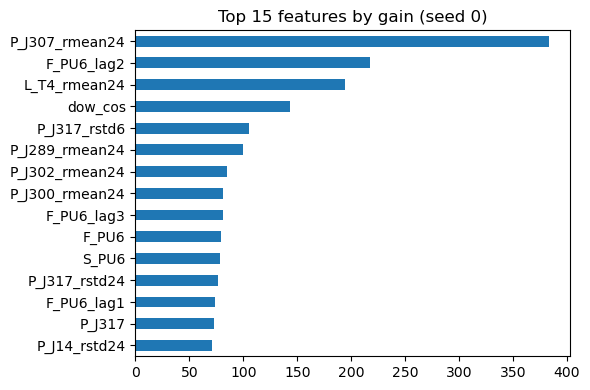

In [5]:
imp = pd.read_csv(f'{R}/xgb/seed0/feature_importance.csv', index_col=0)['gain']
imp.head(15)[::-1].plot.barh(figsize=(6, 4), title='Top 15 features by gain (seed 0)'); plt.tight_layout()

## 2. Ensemble of XGBoost and Isolation Forest

The Transformer is not included yet (its per-hour scores are needed). `max` of calibration percentiles is the fusion rule from the project proposal.

In [6]:
s = pd.read_csv(f'{R}/ensemble/summary.csv')
s[s.norm == 'percentile']

,norm,detectors,fusion,detected,mean_delay,recall,precision,f1,tnr,roc_auc,pr_auc,s_score
0,percentile,xgb,single,4.000,11.667,0.248,0.886,0.388,0.996,0.700,0.486,0.539
1,percentile,iforest,single,6.000,12.111,0.482,0.896,0.627,0.993,0.802,0.624,0.744
2,percentile,xgb+iforest,mean,7.000,9.905,0.104,0.686,0.178,0.993,0.811,0.388,0.678
3,percentile,xgb+iforest,paper,6.333,20.563,0.120,0.689,0.203,0.993,0.742,0.403,0.604
4,percentile,xgb+iforest,max,7.000,19.857,0.691,0.956,0.802,0.996,0.949,0.868,0.803


In [7]:
s[s.norm == 'ratio']

,norm,detectors,fusion,detected,mean_delay,recall,precision,f1,tnr,roc_auc,pr_auc,s_score
5,ratio,xgb,single,4.000,11.583,0.250,0.887,0.390,0.996,0.700,0.490,0.540
6,ratio,iforest,single,6.000,10.556,0.482,0.896,0.627,0.993,0.802,0.624,0.750
7,ratio,xgb+iforest,mean,4.667,17.583,0.248,0.882,0.387,0.996,0.943,0.758,0.563
8,ratio,xgb+iforest,paper,4.000,11.583,0.248,0.886,0.388,0.996,0.915,0.642,0.540
9,ratio,xgb+iforest,max,4.667,12.139,0.254,0.888,0.395,0.996,0.891,0.764,0.578


In [8]:
all_runs = pd.read_csv(f'{R}/ensemble/all_runs.csv')
best = all_runs[(all_runs.norm == 'percentile') & (all_runs.fusion == 'max')]
best[['seed','detected','mean_delay','recall','precision','f1','roc_auc','pr_auc','s_score']]

,seed,detected,mean_delay,recall,precision,f1,roc_auc,pr_auc,s_score
4,0,7,14.428571,0.684932,0.955414,0.797872,0.950121,0.868047,0.826219
14,1,7,22.428571,0.698630,0.956250,0.807388,0.948544,0.868304,0.793280
24,2,7,22.714286,0.689498,0.955696,0.801061,0.949685,0.867348,0.788616


## 3. Per-hour scores of the best ensemble member pair

XGBoost out-of-fold score vs. Isolation Forest score on the labeled attack hours and on the validation block.

In [9]:
x = pd.read_csv(f'{R}/xgb/seed0/xgb_hourly_scores.csv')
f = pd.read_csv(f'{R}/iforest/seed0/iforest_hourly_scores.csv')
m = x.merge(f, on=['source','row'])
m['group'] = m.apply(lambda r: 'validation (clean)' if r.source=='val' else ('calibration (clean)' if r.source=='cal' else ('attack, ATT_FLAG=1' if r.att_flag==1 else 'attack window, -999')), axis=1)
m.groupby('group')[['xgb_score','if_score']].median().round(4)

,xgb_score,if_score
group,,
"attack window, -999",0.0006,0.4288
"attack, ATT_FLAG=1",0.0006,0.4938
calibration (clean),0.0001,0.4224
validation (clean),0.0001,0.4238


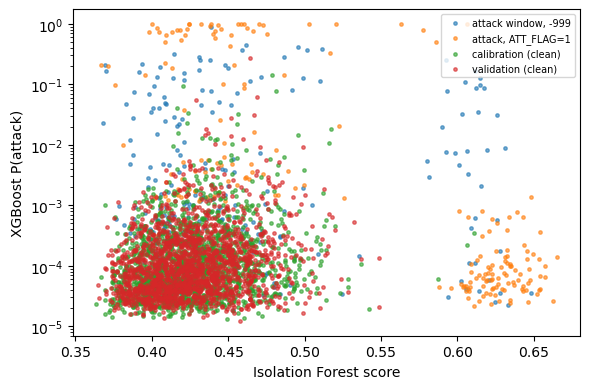

In [10]:
fig, ax = plt.subplots(figsize=(6, 4))
for g, d in m.groupby('group'):
    ax.scatter(d.if_score, d.xgb_score, s=6, label=g, alpha=0.6)
ax.set_yscale('log'); ax.set_xlabel('Isolation Forest score'); ax.set_ylabel('XGBoost P(attack)'); ax.legend(fontsize=7)
plt.tight_layout()